# The Eye searches for the Ring
*Solving an optimization problem, step by step.*

Sauron is looking for the One Ring. Four of his Nazgûl are out riding, and each
of them can sense the Ring. The sense is limited: a Nazgûl feels how far away
the Ring is, but not in which direction, and the feeling is a little off. Each
Nazgûl reports back one number, its distance to the Ring.

Where is the Ring?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import islice

Point = np.ndarray  # (x, y) on the map, in leagues
NOISE = 0.3  # how far off a reading typically is, in leagues

ring = np.array([0.0, 0.0])  # only used to make up the readings
nazguls = np.array([[12.0, -3.0], [13.0, -1.0], [12.5, 1.0], [13.5, 3.0]])

rng = np.random.default_rng(1)
distances = np.linalg.norm(nazguls - ring, axis=1)
readings = distances + NOISE * rng.standard_normal(len(nazguls))
readings

array([12.47299213, 13.28489025, 12.63906733, 13.43836952])

A reading says that the Ring lies somewhere on a circle around that Nazgûl.
With exact readings all four circles would pass through the Ring. The readings
are a little off, so the circles only nearly meet.

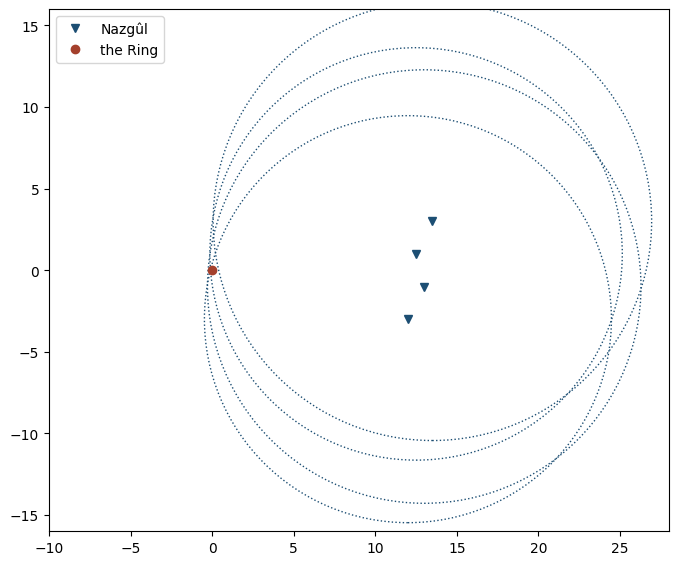

In [2]:
MADDER, PRUSSIAN, VERDIGRIS = '#a4402c', '#1c4e73', '#2b6f68'
OCHRE, CONSTRUCT = '#b58a1e', '#c3c9cf'

def draw_scene():
    plt.figure(figsize=(8, 7))
    for n, d in zip(nazguls, readings):
        circle = plt.Circle(n, d, fill=False, ls=':', color=PRUSSIAN)
        plt.gca().add_patch(circle)
    plt.plot(*nazguls.T, 'v', color=PRUSSIAN, label='Nazgûl')
    plt.plot(*ring, 'o', color=MADDER, label='the Ring')
    plt.axis((-10, 28, -16, 16))
    plt.gca().set_aspect('equal')

draw_scene()
plt.legend();

## I. One dimension, without derivatives

Start with an easier version. Suppose the Ring is known to lie on the East Road,
and that the road is completely straight. A guess is then a single number $s$:
how many leagues along the road from where it starts.

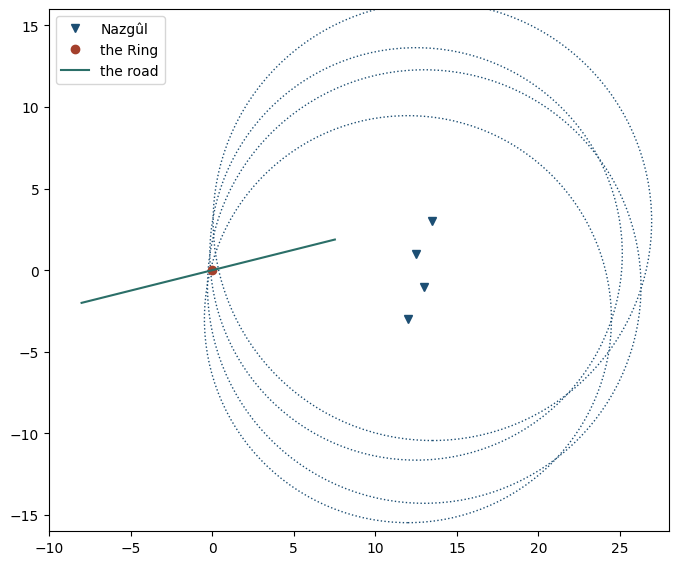

In [3]:
road_start = np.array([-8.0, -2.0])
road_direction = np.array([4.0, 1.0]) / np.sqrt(17)  # unit length

def road(s: float) -> Point:
    return road_start + s * road_direction

draw_scene()
plt.plot(*zip(road(0), road(16)), color=VERDIGRIS, label='the road')
plt.legend();

**How wrong is a guess?** Take a guess $p$ and measure its distance to each
Nazgûl. Had the guess been right, those distances would match the readings. The
difference for Nazgûl $i$ is called its *residual*:

$$r_i(p) = \lVert p - n_i \rVert - d_i$$

where $n_i$ is where the Nazgûl stands and $d_i$ is its reading. In the figure,
the residuals are the red gaps between a guess on the road and the circles.

array([3.76638855, 3.83456578, 4.10386476, 4.63603407])

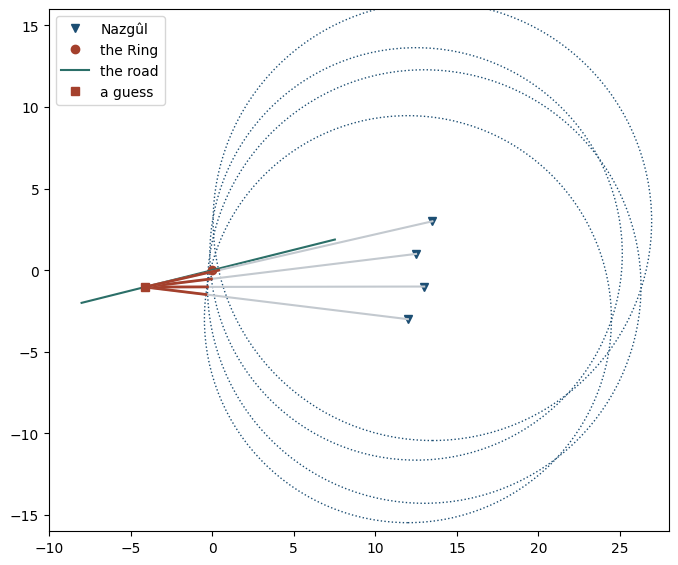

In [4]:
def residuals(p: Point, nazguls=nazguls, d=readings) -> np.ndarray:
    return np.linalg.norm(p - nazguls, axis=1) - d

def draw_residuals(p: Point):
    for n, d in zip(nazguls, readings):
        edge = n + d * (p - n) / np.linalg.norm(p - n)
        plt.plot(*zip(n, p), color=CONSTRUCT)
        plt.plot(*zip(edge, p), color=MADDER, lw=2)
    plt.plot(*p, 's', color=MADDER, label='a guess')

guess = road(4.0)
draw_scene()
plt.plot(*zip(road(0), road(16)), color=VERDIGRIS, label='the road')
draw_residuals(guess)
plt.legend()
residuals(guess)

**The cost.** Square the residuals, so that too far and too near both count, and
add them up. The result is one number, small for a good guess and large for a
bad one:

$$f(p) = \tfrac12 \sum_i r_i(p)^2$$

Every optimization problem has this shape: an input that may be varied, and one
number to make as small as possible. On the road the input is $s$, and the cost
is $\phi(s) = f(\mathrm{road}(s))$.

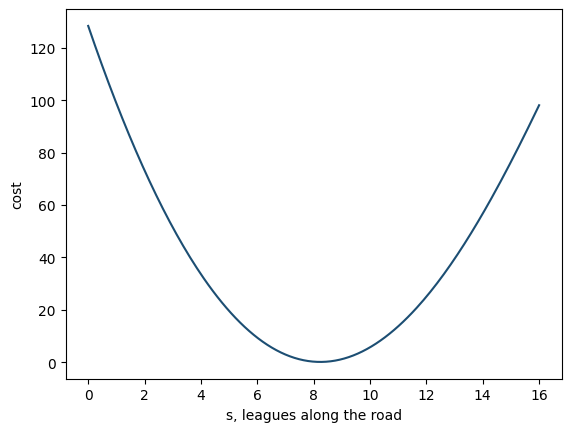

In [5]:
def f(p: Point, nazguls=nazguls, d=readings) -> float:
    return 0.5 * (residuals(p, nazguls, d)**2).sum()

def phi(s: float) -> float:
    return f(road(s))

s = np.linspace(0, 16, 200)
plt.plot(s, [phi(si) for si in s], color=PRUSSIAN)
plt.xlabel('s, leagues along the road'); plt.ylabel('cost');

**Bracketing.** Three points $a < b < c$ with $\phi(b)$ below both ends trap
a minimum in $(a, c)$. Two comparisons, no arithmetic.

In [6]:
a, b, c = 0.0, 8.0, 16.0
print(phi(a), phi(b), phi(c))

128.38383615885124 0.21986065336545324 98.10459166774402


**Halving the bracket.** Probe either side of the middle and keep the side holding
the smaller value. Two evaluations buy half the width.

In [7]:
EPS = 1e-3

def bisect(f, a: float, c: float, steps: int) -> float:
    for _ in range(steps):
        m = (a + c) / 2
        if f(m - EPS) < f(m + EPS):
            c = m
        else:
            a = m
    return (a + c) / 2

bisect(phi, a, c, 10)  # 20 evaluations shrink the bracket a thousandfold

8.2421875

## II. Descent directions and step lengths

The slope says which way is downhill. Write $\rho_i(s) = \lVert \mathrm{road}(s) - n_i \rVert$
for the distance a Nazgûl would see. The chain rule through the square root gives

$$\frac{d\rho_i}{ds} = \frac{(\mathrm{road}(s) - n_i) \cdot u}{\rho_i}, \qquad
\frac{d\phi}{ds} = \sum_i (\rho_i - d_i)\,\frac{d\rho_i}{ds}$$

where $u$ is the road's unit direction. Differentiating once more,
$\frac{d^2\rho_i}{ds^2} = \bigl(1 - (\frac{d\rho_i}{ds})^2\bigr)/\rho_i$, so

$$\frac{d^2\phi}{ds^2} = \sum_i \Bigl(\frac{d\rho_i}{ds}\Bigr)^2 + (\rho_i - d_i)\,\frac{d^2\rho_i}{ds^2}$$

In [8]:
def dphi(s: float) -> tuple[float, float]:
    "First and second derivative of phi."
    d = road(s) - nazguls
    rho = np.linalg.norm(d, axis=1)
    drho = d @ road_direction / rho
    r = rho - readings
    return (r * drho).sum(), (drho**2 + r * (1 - drho**2) / rho).sum()

print(dphi(a)[0], dphi(c)[0])  # downhill to the right at a, to the left at c

-31.487905746590997 22.35126403506933


**Newton in one dimension.** Fit a parabola from the two derivatives and jump to
its bottom. The correct digits double each step.

$$s \leftarrow s - \frac{d\phi/ds}{d^2\phi/ds^2}$$

In [9]:
s = 2.0
for _ in range(5):
    slope, bend = dphi(s)
    s = s - slope / bend
    print(s)

8.090845479209023
8.23714095616052
8.237359246236911
8.23735924673604
8.237359246736041


## III. Several variables

Now drop the road. The Ring may be anywhere on the map, and a guess is a point
with two coordinates. The cost $f$ is the same function as before. Drawn over
the whole map it is a landscape, and the methods from here on walk on it,
looking for its lowest point.

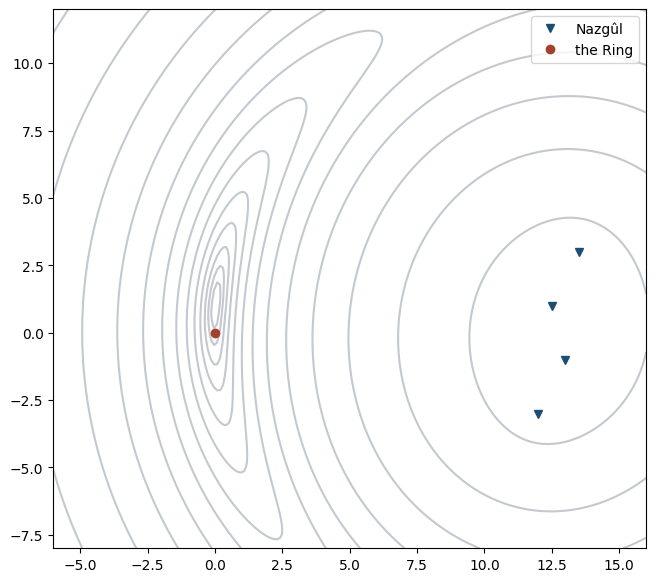

In [10]:
MAP = (-6, 16, -8, 12)

def draw_map(f=f, nazguls=nazguls, extent=MAP):
    x, y = np.meshgrid(np.linspace(*extent[:2], 200),
                       np.linspace(*extent[2:], 200))
    z = np.vectorize(lambda x, y: f(np.array([x, y])))(x, y)
    plt.figure(figsize=(8, 7))
    plt.contour(x, y, z, levels=np.geomspace(0.1, 300, 14), colors=CONSTRUCT)
    plt.plot(*nazguls.T, 'v', color=PRUSSIAN, label='Nazgûl')
    plt.plot(*ring, 'o', color=MADDER, label='the Ring')
    plt.axis(extent)
    plt.gca().set_aspect('equal')

draw_map()
plt.legend();

The methods need derivatives. The gradient of each residual is the unit vector
$u_i$ pointing from Nazgûl $i$ to $p$, written as a row. Stacked, these rows are
the Jacobian $J$ of $r$, and the chain rule gives the gradient and Hessian of $f$:

$$\nabla r_i = \frac{(p - n_i)^{\mathsf T}}{\rho_i} = u_i^{\mathsf T}, \qquad
\nabla f = r^{\mathsf T} J, \qquad
H = \sum_i u_i u_i^{\mathsf T} + \frac{r_i}{\rho_i}\,(I - u_i u_i^{\mathsf T})$$

where $\rho_i = \lVert p - n_i \rVert$ is the distance from the guess to Nazgûl $i$.

In [11]:
def jacobian(p: Point, nazguls=nazguls) -> np.ndarray:
    d = p - nazguls
    return d / np.linalg.norm(d, axis=1)[:, None]

def grad(p: Point, nazguls=nazguls, d=readings) -> np.ndarray:
    return residuals(p, nazguls, d) @ jacobian(p, nazguls)

def hessian(p: Point, nazguls=nazguls, d=readings) -> np.ndarray:
    r = residuals(p, nazguls, d)
    rho = np.linalg.norm(p - nazguls, axis=1)
    bends = (np.outer(u, u) + ri / rhoi * (np.eye(2) - np.outer(u, u))
             for u, ri, rhoi in zip(jacobian(p, nazguls), r, rho))
    return sum(bends)

print(grad(ring), hessian(ring), sep='\n')

[ 0.06351704 -0.12095263]
[[ 3.88255181 -0.02928461]
 [-0.02928461  0.11052619]]


Every method below is a sequence of points, so each is written as a generator that
yields where it stands. `take` collects the first `n` as a path.

In [12]:
def take(points, n: int) -> np.ndarray:
    return np.array(list(islice(points, n)))

def steepest(grad, p: Point, alpha: float):
    while True:
        yield p
        p = p - alpha * grad(p)

def momentum(grad, p: Point, alpha: float, beta: float):
    v = 0
    while True:
        yield p
        v = beta * v - alpha * grad(p)
        p = p + v

def adagrad(grad, p: Point, alpha: float):
    s = 0
    while True:
        yield p
        g = grad(p)
        s = s + g**2
        p = p - alpha / np.sqrt(s) * g

def newton(grad, hessian, p: Point):
    while True:
        yield p
        p = p + np.linalg.solve(hessian(p), -grad(p))

In [13]:
CLOSE = (-3, 5, -2, 7)  # the valley the Ring lies in

def draw_path(path: np.ndarray, color: str, label: str):
    plt.plot(*path.T, '.-', color=color, lw=1, ms=4, label=label)

**Steepest descent with a fixed step.** The step length has to fit the stiffest
direction, and the eigenvalues of the Hessian say how stiff that is.

In [14]:
START = np.array([2.0, 4.0])
ALPHA = 0.4

path = take(steepest(grad, START, ALPHA), 40)
print(path[-1], f(path[-1]))

def values(path: np.ndarray) -> np.ndarray:
    return np.array([f(p) for p in path]).round(3)

print(values(take(steepest(grad, START, 0.6), 8)), 'with a step too long')

[0.08273435 1.54250139] 0.07027065311575958
[  4.03    6.373  10.693  17.96   31.472  52.1    91.434 132.617] with a step too long


**The zig-zag.** With every Nazgûl to the east, the readings pin down how far east
the Ring is and hardly at all how far north. The bowl is long and thin, the
gradient points across the valley, and the ratio of the Hessian's eigenvalues says
how much error each step leaves behind.

In [15]:
lo, hi = np.linalg.eigvalsh(hessian(path[-1]))
kappa = hi / lo
print(f'condition number {kappa:.1f}')
print(f'error left per step {(kappa - 1) / (kappa + 1):.3f}')

condition number 32.4
error left per step 0.940


**Momentum, a step length per coordinate, and Newton**, all on the identical landscape.

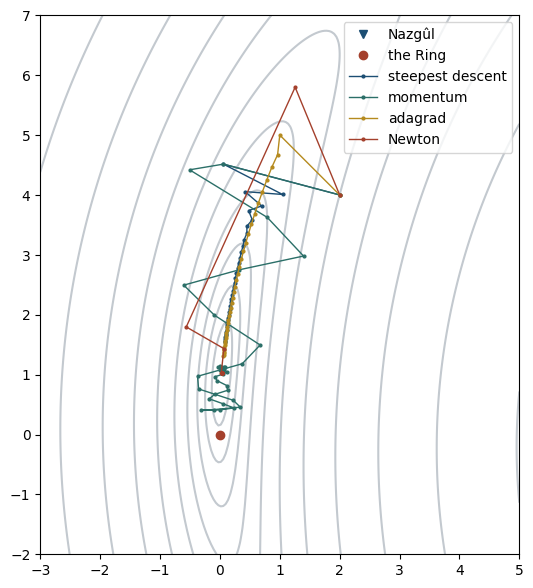

In [16]:
draw_map(extent=CLOSE)
draw_path(take(steepest(grad, START, ALPHA), 40), PRUSSIAN, 'steepest descent')
draw_path(take(momentum(grad, START, ALPHA, 0.8), 40), VERDIGRIS, 'momentum')
draw_path(take(adagrad(grad, START, 1.0), 40), OCHRE, 'adagrad')
draw_path(take(newton(grad, hessian, START), 40), MADDER, 'Newton')
plt.legend();

## IV. Least squares

Squaring a reading turns it into a circle equation,
$\lVert p \rVert^2 - 2\,n_i^{\mathsf T} p + \lVert n_i \rVert^2 = d_i^2$.
The $\lVert p \rVert^2$ term is the same in every one, so subtracting the first
equation from the others leaves equations that are *linear* in $p$:

$$2\,(n_0 - n_i)^{\mathsf T} p = d_i^2 - d_0^2 - \lVert n_i \rVert^2 + \lVert n_0 \rVert^2$$

Three equations, two unknowns, and noisy right-hand sides: linear least squares,
solved by the normal equations $A^{\mathsf T} A\,p = A^{\mathsf T} y$.

In [17]:
A = 2 * (nazguls[0] - nazguls[1:])
y = (readings[1:]**2 - readings[0]**2
     - (nazguls[1:]**2).sum(axis=1) + nazguls[0] @ nazguls[0])

linear = np.linalg.solve(A.T @ A, A.T @ y)
print(linear, f(linear))
print(A.T @ (y - A @ linear), 'the residual is orthogonal to every column of A')

[-0.73846259  0.81345589] 1.1515064499768468
[-1.77635684e-15 -7.10542736e-15] the residual is orthogonal to every column of A


**Gauss–Newton.** Linearize the residual, $r(p + h) \approx r(p) + Jh$, and the
step solves the normal equations with $J$ for $A$ and $-r$ for $y$. Compare
$J^{\mathsf T} J$ with the Hessian above: it is the first sum, the part that
needs no second derivatives.

$$J^{\mathsf T} J\,h = -J^{\mathsf T} r$$

In [18]:
def gauss_newton(residuals, jacobian, p: Point):
    while True:
        yield p
        r, J = residuals(p), jacobian(p)
        p = p + np.linalg.solve(J.T @ J, -J.T @ r)

values(take(gauss_newton(residuals, jacobian, linear), 5))

array([1.152, 0.054, 0.054, 0.054, 0.054])

**Levenberg–Marquardt.** From a poor start the linearization is believed too far,
and a Gauss–Newton step can make things worse. Adding $\lambda I$ shortens the step
towards the gradient direction. Raise $\lambda$ when a step fails, lower it when it
helps.

$$(J^{\mathsf T} J + \lambda I)\,h = -J^{\mathsf T} r$$

In [19]:
def levenberg_marquardt(f, residuals, jacobian, p: Point, lam: float = 1.0):
    while True:
        yield p
        r, J = residuals(p), jacobian(p)
        h = np.linalg.solve(J.T @ J + lam * np.eye(2), -J.T @ r)
        if f(p + h) < f(p):
            p, lam = p + h, lam / 10
        else:
            lam = lam * 10

far = np.array([5.0, 8.0])
print(values(take(gauss_newton(residuals, jacobian, far), 6)))
print(values(take(levenberg_marquardt(f, residuals, jacobian, far), 6)))

[10.162 14.563  0.08   0.054  0.054  0.054]
[10.162  4.047  1.956  0.699  0.054  0.054]


## V. The wider landscape

**Two minima and a saddle.** Only two Nazgûl report: the Witch-king, and Khamûl
riding the north road. Two distance readings are two circles, and circles cross
twice: the two solutions are mirror images across the line joining the Nazgûl,
with a saddle between them.

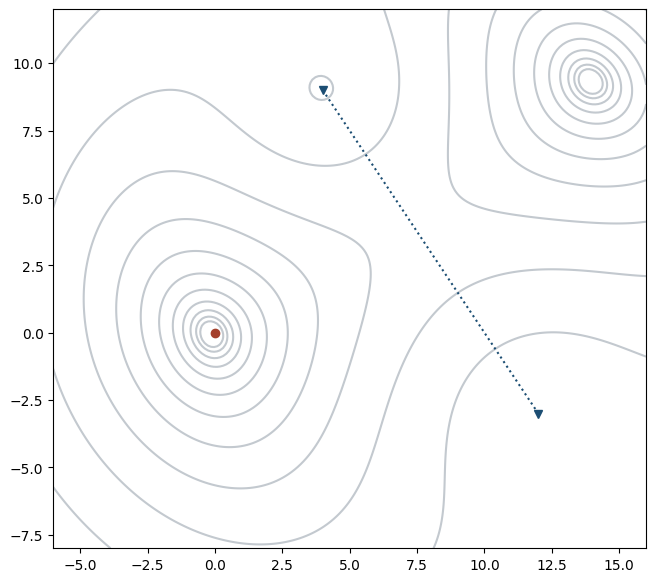

In [20]:
two_nazguls = np.array([[12.0, -3.0], [4.0, 9.0]])
two_readings = readings[0], np.linalg.norm(two_nazguls[1] - ring) + 0.1

f2 = lambda p: f(p, two_nazguls, two_readings)
grad2 = lambda p: grad(p, two_nazguls, two_readings)
hessian2 = lambda p: hessian(p, two_nazguls, two_readings)

draw_map(f2, two_nazguls)
plt.plot(*two_nazguls.T, ':', color=PRUSSIAN);

Newton finds where the gradient vanishes and does not ask which way the surface
bends. Started on the line between the two Nazgûl, it stays on it by symmetry and
lands on the saddle, where the Hessian's eigenvalues have opposite signs.

In [21]:
saddle = take(newton(grad2, hessian2, two_nazguls.mean(axis=0)), 10)[-1]
print(saddle, np.linalg.eigvalsh(hessian2(saddle)))

[7.2999311  4.05010336] [-1.14440546  2.        ]


**Multistart.** Descent only ever goes down, so the basin it starts in is the basin
it ends in. Many random starts find both.

array([[-0.1, -0.1],
       [13.9,  9.3]])

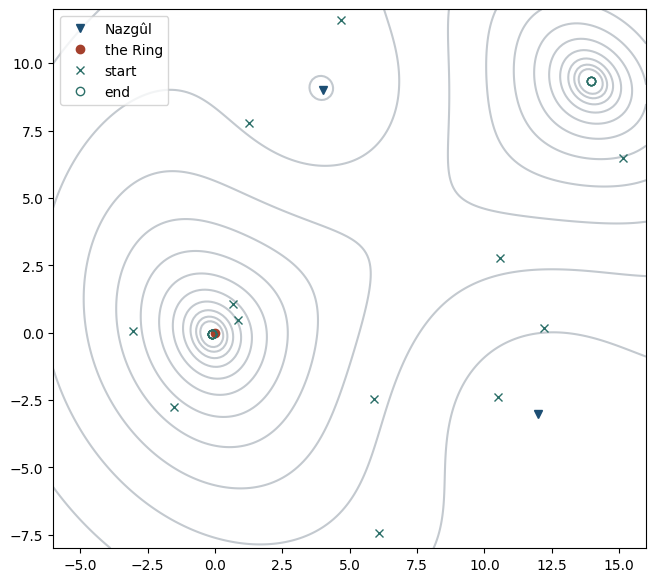

In [22]:
starts = rng.uniform(MAP[::2], MAP[1::2], size=(12, 2))
ends = np.array([take(steepest(grad2, p, 0.5), 200)[-1] for p in starts])

draw_map(f2, two_nazguls)
plt.plot(*starts.T, 'x', color=VERDIGRIS, label='start')
plt.plot(*ends.T, 'o', color=VERDIGRIS, mfc='none', label='end')
plt.legend()
np.unique(np.round(ends, 1), axis=0)

**Back on the road.** Searching along the road was a constrained problem:
minimize $f$ subject to $g(p) = 0$, where $g$ measures the distance off the road.
At the answer the gradient of $f$ need not vanish; it is parallel to the gradient
of $g$, the road's normal. Nothing is left to gain along the road, only across it.

$$\nabla f = \lambda\,\nabla g$$

In [23]:
on_road = road(s)  # where Newton stopped on the road
normal = np.array([-road_direction[1], road_direction[0]])
print(grad(on_road), 'the gradient on the road')
print(grad(on_road) @ normal * normal, 'lambda times the normal')

[ 0.03023595 -0.12094381] the gradient on the road
[ 0.03023595 -0.12094381] lambda times the normal


**Stochastic gradient descent.** The readings arrive one at a time, and the
estimate moves after each. One term of the sum stands in for the whole gradient,
scaled up by the number of terms. The path never settles; it ends in a cloud
around the minimum.

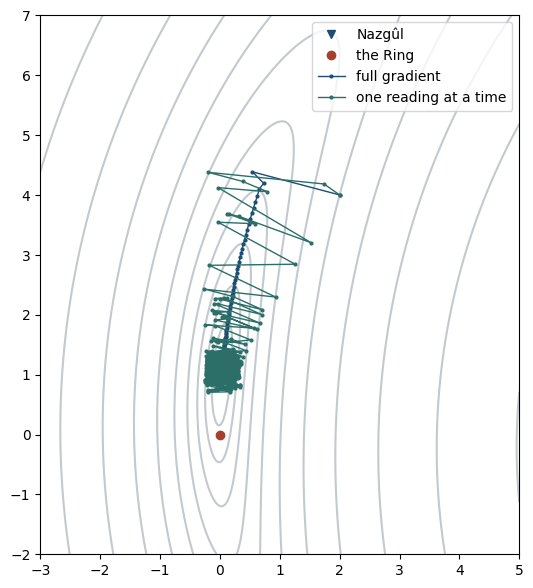

In [24]:
def stochastic(p: Point, alpha: float):
    m = len(nazguls)
    while True:
        for i in rng.permutation(m):
            yield p
            p = p - alpha * m * grad(p, nazguls[[i]], readings[[i]])

draw_map(extent=CLOSE)
draw_path(take(steepest(grad, START, 0.3), 300), PRUSSIAN, 'full gradient')
draw_path(take(stochastic(START, 0.3), 300), VERDIGRIS, 'one reading at a time')
plt.legend();